# Geometry-conditioned language mapping from exported iPhone LiDAR

This notebook repairs the original geometry and evaluates held-out consistency before generating maps. The research direction is a hypothesis, not a novelty or state-of-the-art claim. Ground-truth metric depth, timestamps, intrinsics and confidence maps are absent. See `research/RESEARCH_REVIEW.md` for the full review and related work.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
assert (ROOT / "dataset/content/vlmaps_dataset/my_custom_scene/poses.txt").exists()
sys.path.insert(0, str(ROOT / ".packages"))
sys.path.insert(0, str(ROOT / "research"))
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["MPLCONFIGDIR"] = str(ROOT / ".matplotlib")
os.environ["YOLO_CONFIG_DIR"] = str(ROOT / ".yolo")
import numpy as np
import pandas as pd
from IPython.display import display, Image, Video
import geometry_probe as probe
import improve_mapping as mapping
import verify_semantics as semantic
import query_map as language
print("Workspace:", ROOT)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Workspace: D:\VLM-maps


## Validate inputs and evidence provenance

The user reports iPhone LiDAR. Native ARKit depth is metric, but these files appear quantized. We infer decoding in pose translation units and preserve that uncertainty.

Frames: 2091
Sample raw depth: [  0.  10. 135. 250. 255.]


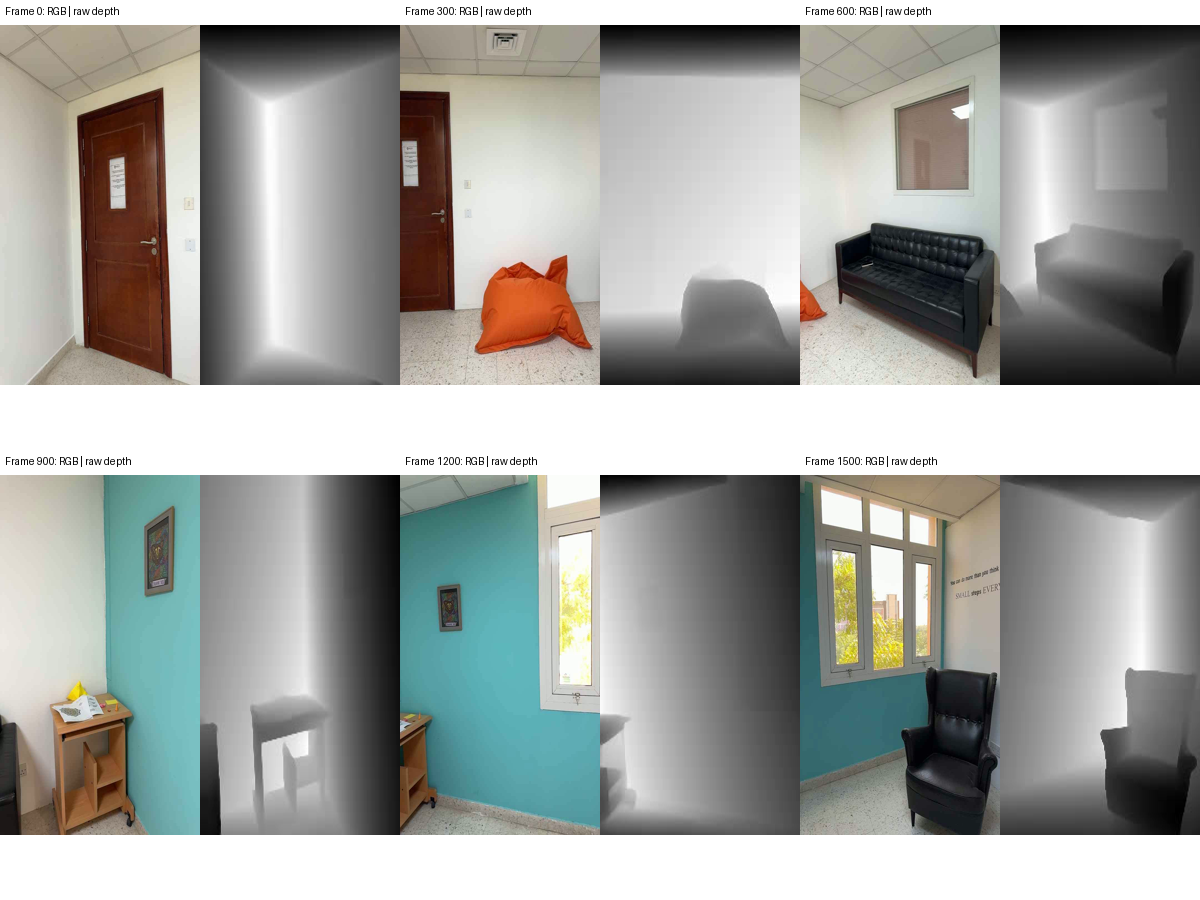

In [2]:
DATA = probe.DATA
poses = np.loadtxt(DATA / "poses.txt")
rgb_files = sorted((DATA / "rgb").glob("*.png"))
depth_files = sorted((DATA / "depth").glob("*.npy"))
assert len(rgb_files) == len(depth_files) == len(poses) == 2091
assert [p.stem for p in rgb_files] == [p.stem for p in depth_files]
assert poses.shape[1] == 7 and np.isfinite(poses).all()
print("Frames:", len(poses))
print("Sample raw depth:", np.percentile(np.load(depth_files[0]), [0, 1, 50, 99, 100]))
display(Image(filename=str(ROOT / "research/input_contact_sheet.png")))

## Recover camera convention and focal from training correspondences

Compare camera-to-world/world-to-camera and OpenCV/ARKit axes. Hold out every fifth anchor pair; infer only a scalar focal while retaining the centre assumption.

In [3]:
probe.run()
diagnostics = json.loads((ROOT / "research/geometry_diagnostics.json").read_text())
print("Selected mode:", diagnostics["selected_mode"])
display(pd.DataFrame(diagnostics["camera_candidates"]).head(8))

Camera candidates: [
  {
    "mode": "c2w_opengl",
    "focal_half_resolution": 350.0,
    "median_epipolar_px": 0.3310302935616077,
    "positive_depth_fraction": 0.9658658420551856,
    "samples": 8408,
    "split": "training anchors only"
  },
  {
    "mode": "c2w_opengl",
    "focal_half_resolution": 375.0,
    "median_epipolar_px": 0.9054479090386699,
    "positive_depth_fraction": 0.8790437678401523,
    "samples": 8408,
    "split": "training anchors only"
  },
  {
    "mode": "c2w_opengl",
    "focal_half_resolution": 300.0,
    "median_epipolar_px": 1.1855556049963987,
    "positive_depth_fraction": 0.8903425309229306,
    "samples": 8408,
    "split": "training anchors only"
  },
  {
    "mode": "c2w_opengl",
    "focal_half_resolution": 400.0,
    "median_epipolar_px": 1.471307224052583,
    "positive_depth_fraction": 0.7615366317792579,
    "samples": 8408,
    "split": "training anchors only"
  },
  {
    "mode": "c2w_opengl",
    "focal_half_resolution": 250.0,
    "media

Camera selected c2w_opengl focal 343.7862369829403 triangulated samples 10518


Selected mode: c2w_opengl


,mode,focal_half_resolution,median_epipolar_px,positive_depth_fraction,samples,split
0,c2w_opengl,350.0,0.331030,0.965866,8408,training anchors only
1,c2w_opengl,375.0,0.905448,0.879044,8408,training anchors only
2,c2w_opengl,300.0,1.185556,0.890343,8408,training anchors only
3,c2w_opengl,400.0,1.471307,0.761537,8408,training anchors only
4,c2w_opengl,250.0,2.629660,0.779971,8408,training anchors only
5,c2w_opengl,450.0,2.556047,0.693387,8408,training anchors only
6,c2w_opengl,500.0,3.619956,0.658539,8408,training anchors only
7,w2c_opencv,300.0,5.173952,0.547952,9426,training anchors only


## Recover depth and evaluate before filtering

Positive monotonic decoder spans prevent underconstrained frames from reversing depth. Pair holdout excludes duplicate image keypoints. Temporal-block depth evaluation and unfiltered 3D disagreement expose failure tails; these metrics are consistency proxies, not ground-truth accuracy.

Calibration evaluation: {
  "depth_holdout": [
    {
      "method": "original_framewise_pseudo_depth",
      "samples": 2052,
      "valid_fraction": 1.0,
      "median_abs_relative_error": 0.31528139613957173,
      "mean_abs_relative_error": 0.3231641576638692,
      "rmse_pose_units": 0.830095191602898,
      "fraction_within_10_percent": 0.21003898635477583
    },
    {
      "samples": 2052,
      "valid_fraction": 1.0,
      "median_abs_relative_error": 0.15230362507487583,
      "mean_abs_relative_error": 0.1713161530012121,
      "rmse_pose_units": 0.4341077746151839,
      "fraction_within_10_percent": 0.31773879142300193,
      "method": "single_global_affine_depth"
    },
    {
      "samples": 2052,
      "valid_fraction": 1.0,
      "median_abs_relative_error": 0.03760139582749589,
      "mean_abs_relative_error": 0.08620253206711483,
      "rmse_pose_units": 0.3017775333617415,
      "fraction_within_10_percent": 0.8084795321637427,
      "method": "temporally_regularize

,method,samples,valid_fraction,median_abs_relative_error,mean_abs_relative_error,rmse_pose_units,fraction_within_10_percent
0,original_framewise_pseudo_depth,2052,1.0,0.315281,0.323164,0.830095,0.210039
1,single_global_affine_depth,2052,1.0,0.152304,0.171316,0.434108,0.317739
2,temporally_regularized_affine_depth,2052,1.0,0.037601,0.086203,0.301778,0.808480
3,temporally_regularized_inverse_depth,2052,1.0,0.042188,0.080716,0.258254,0.802632


,heldout_matches,median_epipolar_error_half_resolution_px,p90_epipolar_error_half_resolution_px
original,2190.0,20.806560,61.008401
axis_fix_only,2190.0,1.036835,4.143864
axis_and_focal_fix,2190.0,0.297697,1.719185


,samples,median_cross_view_3d_disagreement_pose_units,p90_disagreement_pose_units,pair_cluster_bootstrap_95_interval
original,2183,0.403383,1.04796,"[0.29298199518066564, 0.6793399581853629]"
axis_and_focal_fix_only,2183,0.121291,0.435224,"[0.09179281718734991, 0.1768105721116232]"
geometry_and_depth_calibrated,2183,0.078756,0.960231,"[0.052487590577381, 0.13406112423469188]"


Temporal block depth test: {'samples': 2410, 'valid_fraction': 1.0, 'median_abs_relative_error': 0.035642929372224304, 'mean_abs_relative_error': 0.0675860346842215, 'rmse_pose_units': 0.2114150713655537, 'fraction_within_10_percent': 0.8464730290456431, 'note': 'All depth anchors touching withheld 200-frame blocks removed. Intrinsics fixed from camera experiment; this is a depth calibration robustness test.'}


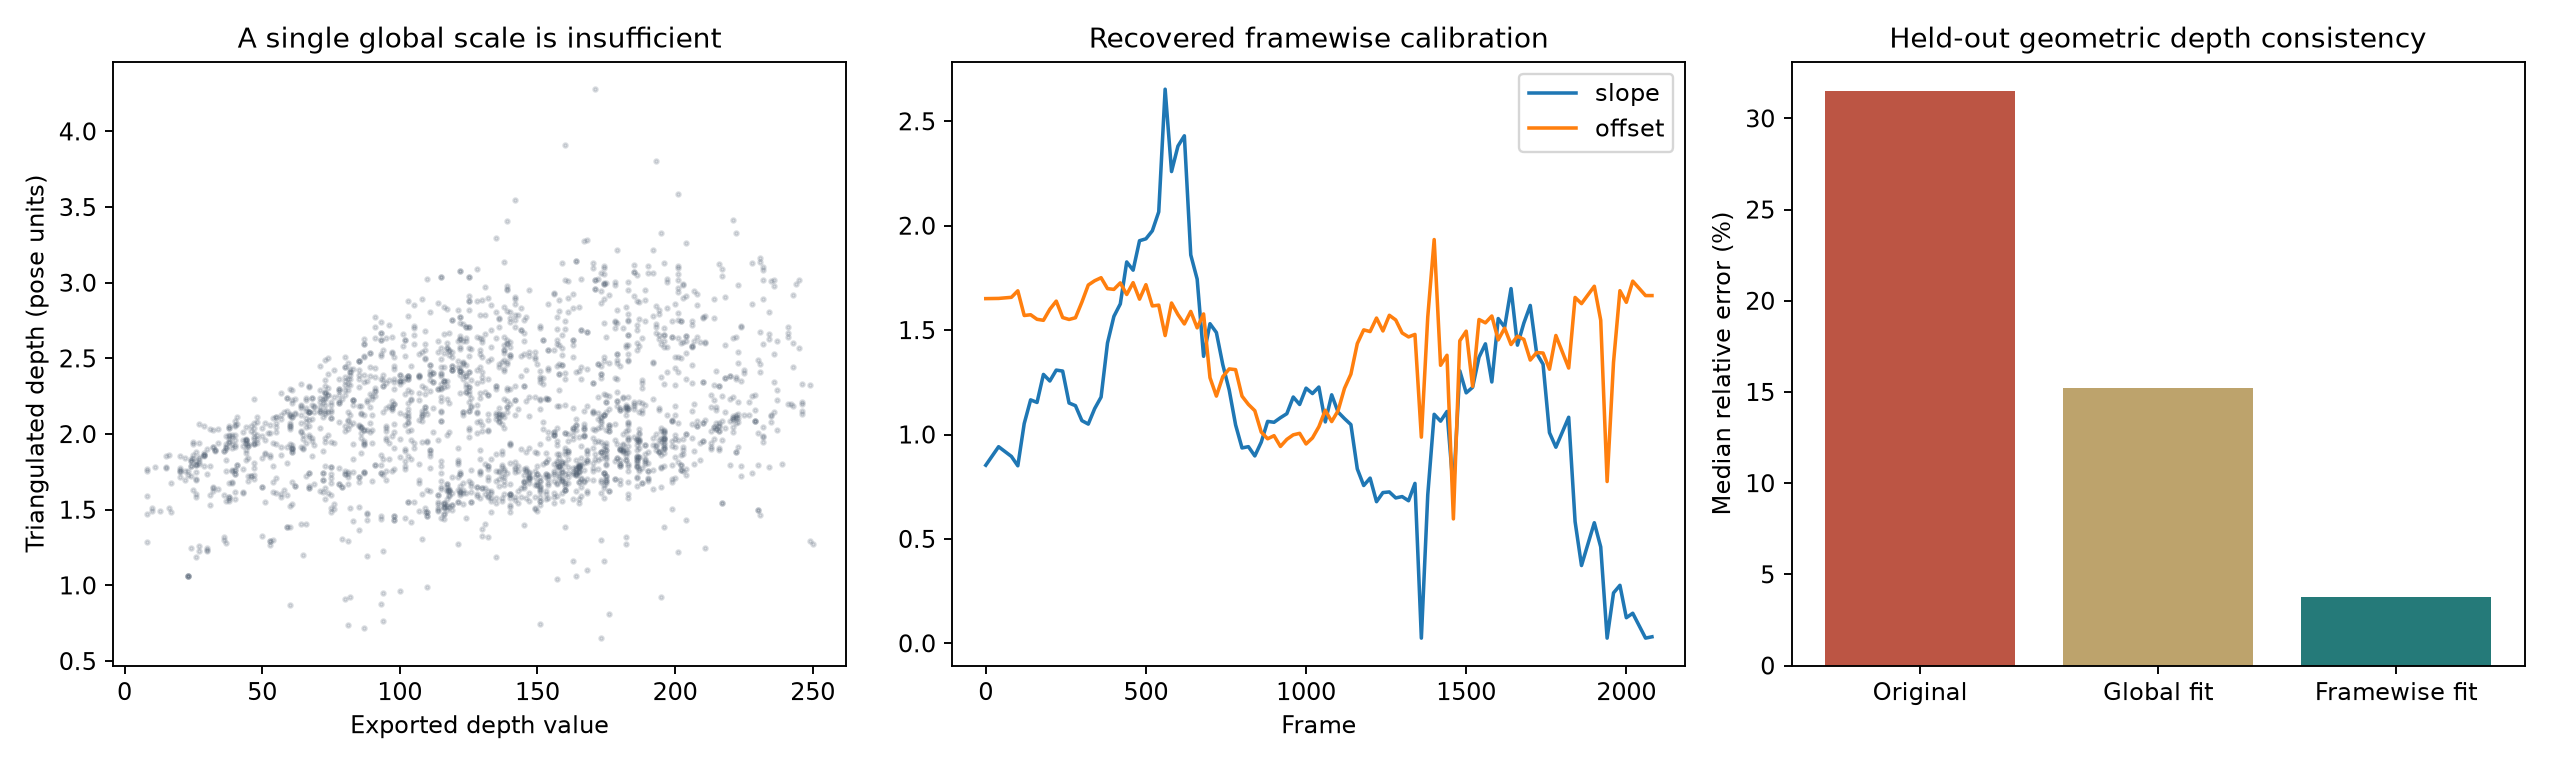

In [4]:
model, Khalf, mode, anchors, metrics = mapping.calibrate()
display(pd.DataFrame(metrics["depth_holdout"]))
display(pd.DataFrame(metrics["geometry_holdout"]).T)
display(pd.DataFrame(metrics["unfiltered_correspondence_fusion_holdout"]).T)
print("Temporal block depth test:", metrics["temporal_block_depth_holdout"])
display(Image(filename=str(mapping.OUT / "calibration_evaluation.png")))

## Map supported surfaces and preserve unknown space

Translation/rotation keyframes, cross-view consistency, one vote per view per voxel, and calibration-quality weighting replace raw density. Ray evidence is sampled near camera height, so this is an exploratory map, not a complete navigation costmap.

Cross-view mapping 0 / 73


Cross-view mapping 20 / 73


Cross-view mapping 40 / 73


Cross-view mapping 60 / 73


Mapping: {"keyframes": 73, "original_final_keyframes": 419, "before_consistency_points": 891911, "cross_view_supported_points": 758875, "fused_voxels": 158109, "multi_view_supported_voxels": 91884, "runtime_seconds": 5.605075899999974, "voxel_size_pose_units": 0.035, "minimum_independent_keyframe_views": 2, "memory_strategy": "bounded keyframe depth cache and early pixel sampling; sparse calibration; NumPy aggregation; no dense 10M-point float64 concatenation"}


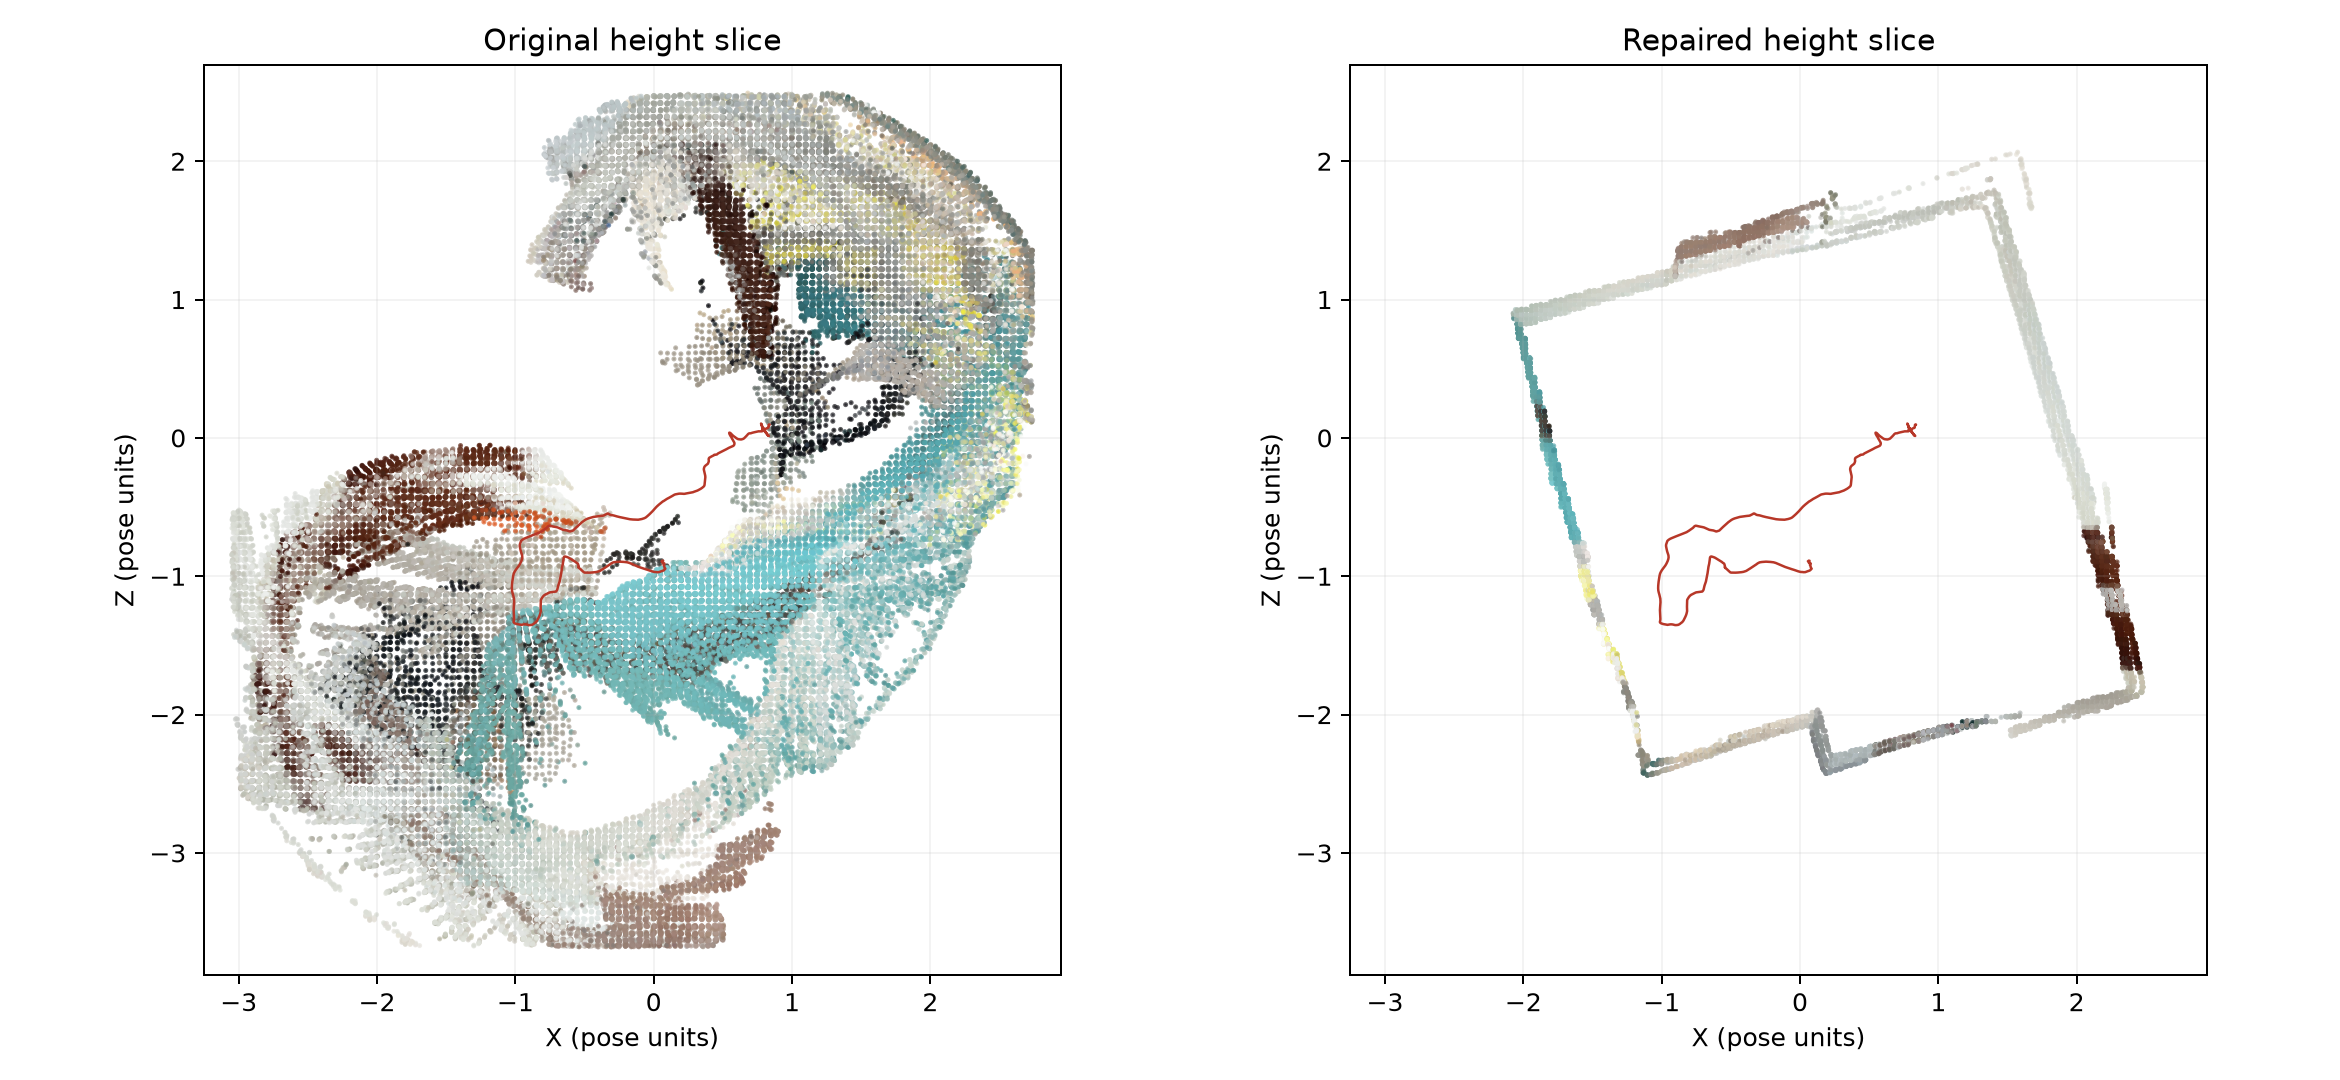

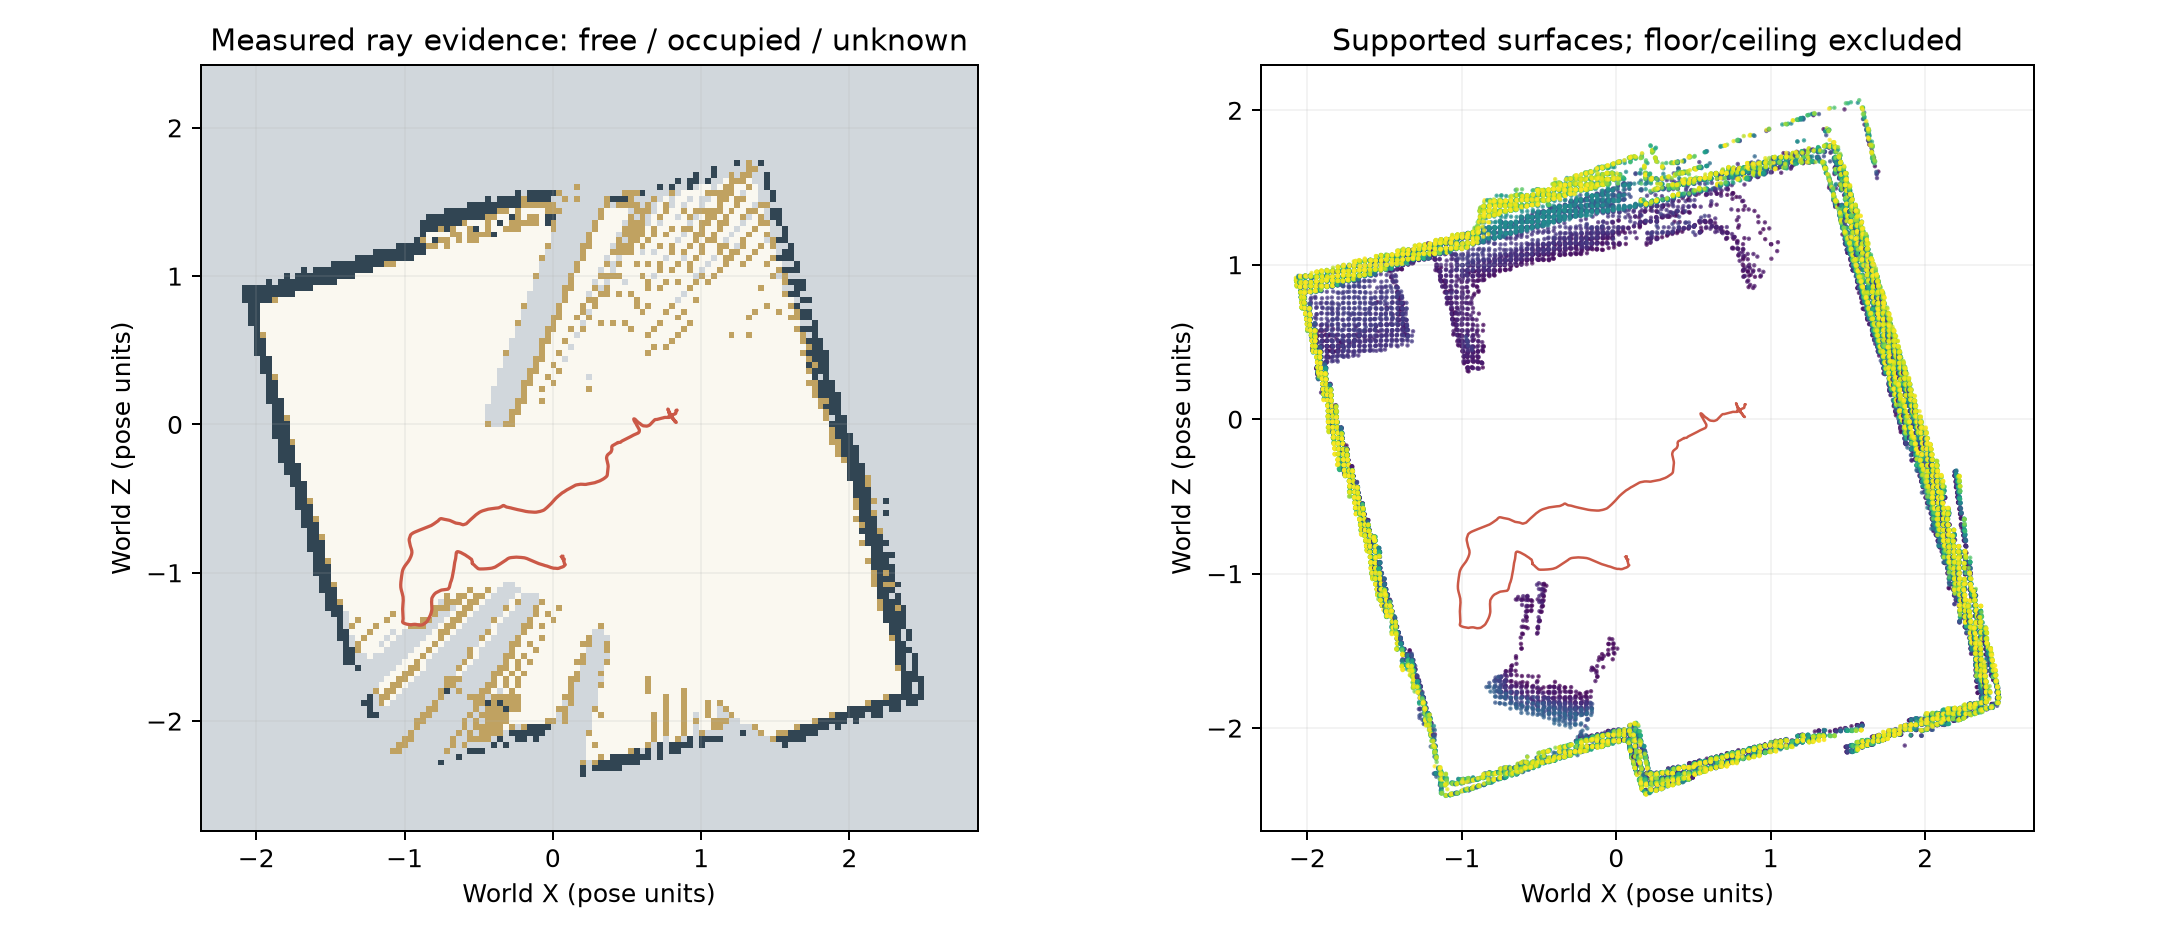

In [5]:
points, colors, selected, Kdepth, R, t, frames, rays = mapping.mapping(model, Khalf, mode, poses)
map_image, extent = mapping.ray_map(points, selected, t, rays)
mapping.comparison(points, colors, poses)
display(Image(filename=str(mapping.OUT / "before_after_height_slice.png")))
display(Image(filename=str(mapping.OUT / "evidence_map.png")))

## Verify semantic hypotheses with text-image evidence

YOLO supplies proposals; CLIP tests an indoor vocabulary and can return unresolved. Cosine scores are not calibrated probabilities. Position support and class correctness remain separate.

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP crops 12 / 55


CLIP crops 24 / 55


CLIP crops 36 / 55


CLIP crops 48 / 55


CLIP crops 55 / 55


{
  "model": "openai/clip-vit-base-patch32",
  "proposals": 55,
  "accepted": 34,
  "unresolved": 21,
  "original_bed_proposals": 15,
  "bed_proposals_reidentified_as_beanbag": 13,
  "vocabulary": {
    "beanbag": [
      "beanbag chair",
      "bean bag seat"
    ],
    "bed": [
      "bed with mattress",
      "bed"
    ],
    "armchair": [
      "armchair",
      "single upholstered chair"
    ],
    "sofa": [
      "sofa",
      "couch"
    ],
    "office chair": [
      "office chair",
      "desk chair"
    ],
    "table": [
      "table",
      "small side table"
    ],
    "shelf": [
      "shelving unit",
      "bookcase"
    ],
    "cabinet": [
      "cabinet",
      "cupboard"
    ],
    "refrigerator": [
      "refrigerator",
      "fridge"
    ],
    "door": [
      "door",
      "wooden door"
    ],
    "window": [
      "window",
      "glass window"
    ],
    "person": [
      "person",
      "human"
    ],
    "lamp": [
      "lamp",
      "light fixture"
    ],
    "

,class_name,cluster_id,world_x,world_z,independent_viewpoints,mean_confidence,spread_radius,cov_xx,cov_xz,cov_zz,status
0,armchair,0,-0.361639,-1.463634,3,0.821796,0.312571,0.093855,0.003072,0.095247,tentative
1,beanbag,0,1.304402,0.074909,6,0.779947,0.219735,0.030849,-0.005452,0.046578,position_supported
2,sofa,0,-0.171536,0.712027,5,0.834908,0.556358,0.294073,0.057208,0.097866,tentative


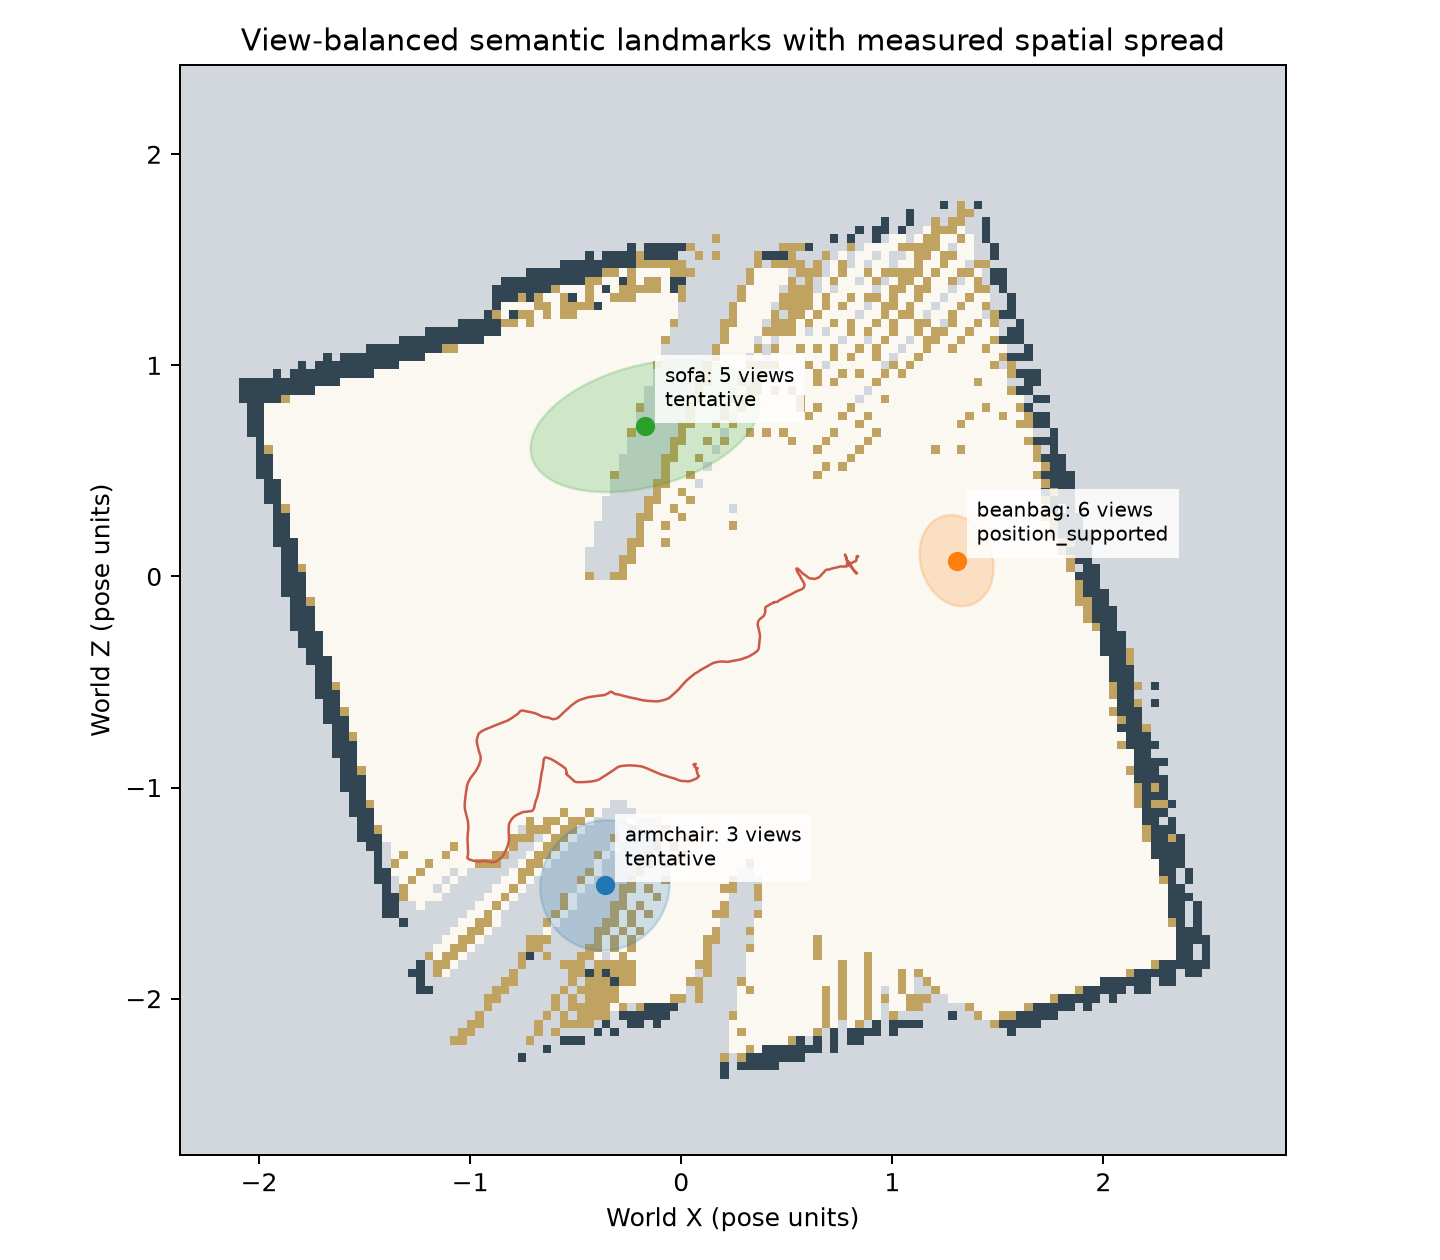

In [6]:
mapping.semantic_landmarks(model, Kdepth, R, t, selected, frames, map_image, extent)
semantic.main()
mapping.semantic_landmarks(model, Kdepth, R, t, selected, frames, map_image, extent)
display(pd.read_csv(mapping.OUT / "semantic_landmarks.csv"))
display(Image(filename=str(mapping.OUT / "semantic_evidence_map.png")))

## Sparse language retrieval with abstention

Use pooled independent-view CLIP region embeddings. This does not provide dense VLMaps semantics or guarantee proposal recall. A candidate can still have tentative spatial support.

In [7]:
import torch
torch.set_num_threads(4)
records, embeddings = language.build_index()
clip = semantic.CLIPModel.from_pretrained(ROOT / ".models/clip", local_files_only=True).eval()
processor = semantic.CLIPProcessor.from_pretrained(ROOT / ".models/clip", local_files_only=True)
queries = ["an orange beanbag chair", "a black leather sofa", "a refrigerator"]
query_results = [language.query(q, clip, processor, records, embeddings) for q in queries]
mapping.dump("language_queries.json", query_results)
print(json.dumps(query_results, indent=2))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[
  {
    "query": "an orange beanbag chair",
    "status": "candidate",
    "cosine_similarity": 0.37251843415313557,
    "margin": 0.11501366333520541,
    "probability": null,
    "note": "Similarity heuristic over sparse detected regions; candidate position can remain tentative.",
    "landmark": {
      "class_name": "beanbag",
      "cluster_id": 0,
      "world_x": 1.304402041923629,
      "world_z": 0.0749086067027325,
      "independent_viewpoints": 6,
      "mean_confidence": 0.7799472212791443,
      "spread_radius": 0.2197347079115582,
      "cov_xx": 0.0308492006040524,
      "cov_xz": -0.0054522856114642,
      "cov_zz": 0.0465782152389727,
      "status": "position_supported",
      "embedding_views": 6
    }
  },
  {
    "query": "a black leather sofa",
    "status": "candidate",
    "cosine_similarity": 0.3720058420042102,
    "margin": 0.0538580567002353,
    "probability": null,
    "note": "Similarity heuristic over sparse detected regions; candidate position can re

## VLMM-inspired motion attributes and latest research

Based on [VLMM v2 (August 2026)](https://arxiv.org/abs/2607.16173v2), with decoder-quality-aware motion covariance as the candidate extension. Related work: [Memory for Attention v2 (September)](https://arxiv.org/abs/2607.23797v2), [SuperMap (RSS 2026)](https://arxiv.org/abs/2608.22896), [ChronoGraph v2 (October)](https://arxiv.org/abs/2609.39665v2). The CPU implementation uses DIS flow and box regions; it is not a benchmark reproduction. Movability is separate from observed motion; lack of ground truth prevents motion accuracy claims.

Motion pair 215 235


Motion pair 235 255


Motion pair 255 275


Motion pair 295 315


Motion pair 335 355


...

Motion pair 1740 1760


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

{
  "reference": "https://arxiv.org/abs/2607.16173v2",
  "adaptation": "CPU DIS flow, eroded box regions, static-background trimmed rigid fit; not paper reproduction",
  "objects": 3,
  "states": {
    "movable_not_observed_moving": 3
  },
  "motion_observation_pairs": 33,
  "sensor_only_pixel_flag_fraction_mean": 0.16631161266154623,
  "with_export_uncertainty_pixel_flag_fraction_mean": 0.04285880873895955,
  "limitation": "Real sequence has no annotated moving-object ground truth; flag fractions are diagnostics, not false-positive rates or recall. Noise inflation alone can suppress true motion. Synthetic static and moving tests are separate."
}


,class_name,observed_motion_score,movability_prior_score,motion_class,eligible_motion_pairs
0,armchair,1.300741,0.736576,movable_not_observed_moving,3
1,beanbag,0.750720,0.702741,movable_not_observed_moving,12
2,sofa,1.211062,0.787186,movable_not_observed_moving,13


[
  {
    "query": "what could be moved?",
    "intent": "movability",
    "semantic": "",
    "matches": [
      {
        "id": "armchair_0",
        "class_name": "armchair",
        "motion_class": "movable_not_observed_moving",
        "position": [
          -0.3616387051624138,
          -1.463634000108618
        ],
        "motion_reliability_score": 0.0,
        "reobservation_priority": 0.562571249204158
      },
      {
        "id": "beanbag_0",
        "class_name": "beanbag",
        "motion_class": "movable_not_observed_moving",
        "position": [
          1.304402041923629,
          0.0749086067027325
        ],
        "motion_reliability_score": 0.0,
        "reobservation_priority": 0.4697347079115582
      },
      {
        "id": "sofa_0",
        "class_name": "sofa",
        "motion_class": "movable_not_observed_moving",
        "position": [
          -0.1715363144694699,
          0.7120270769493362
        ],
        "motion_reliability_score": 0.0,
    

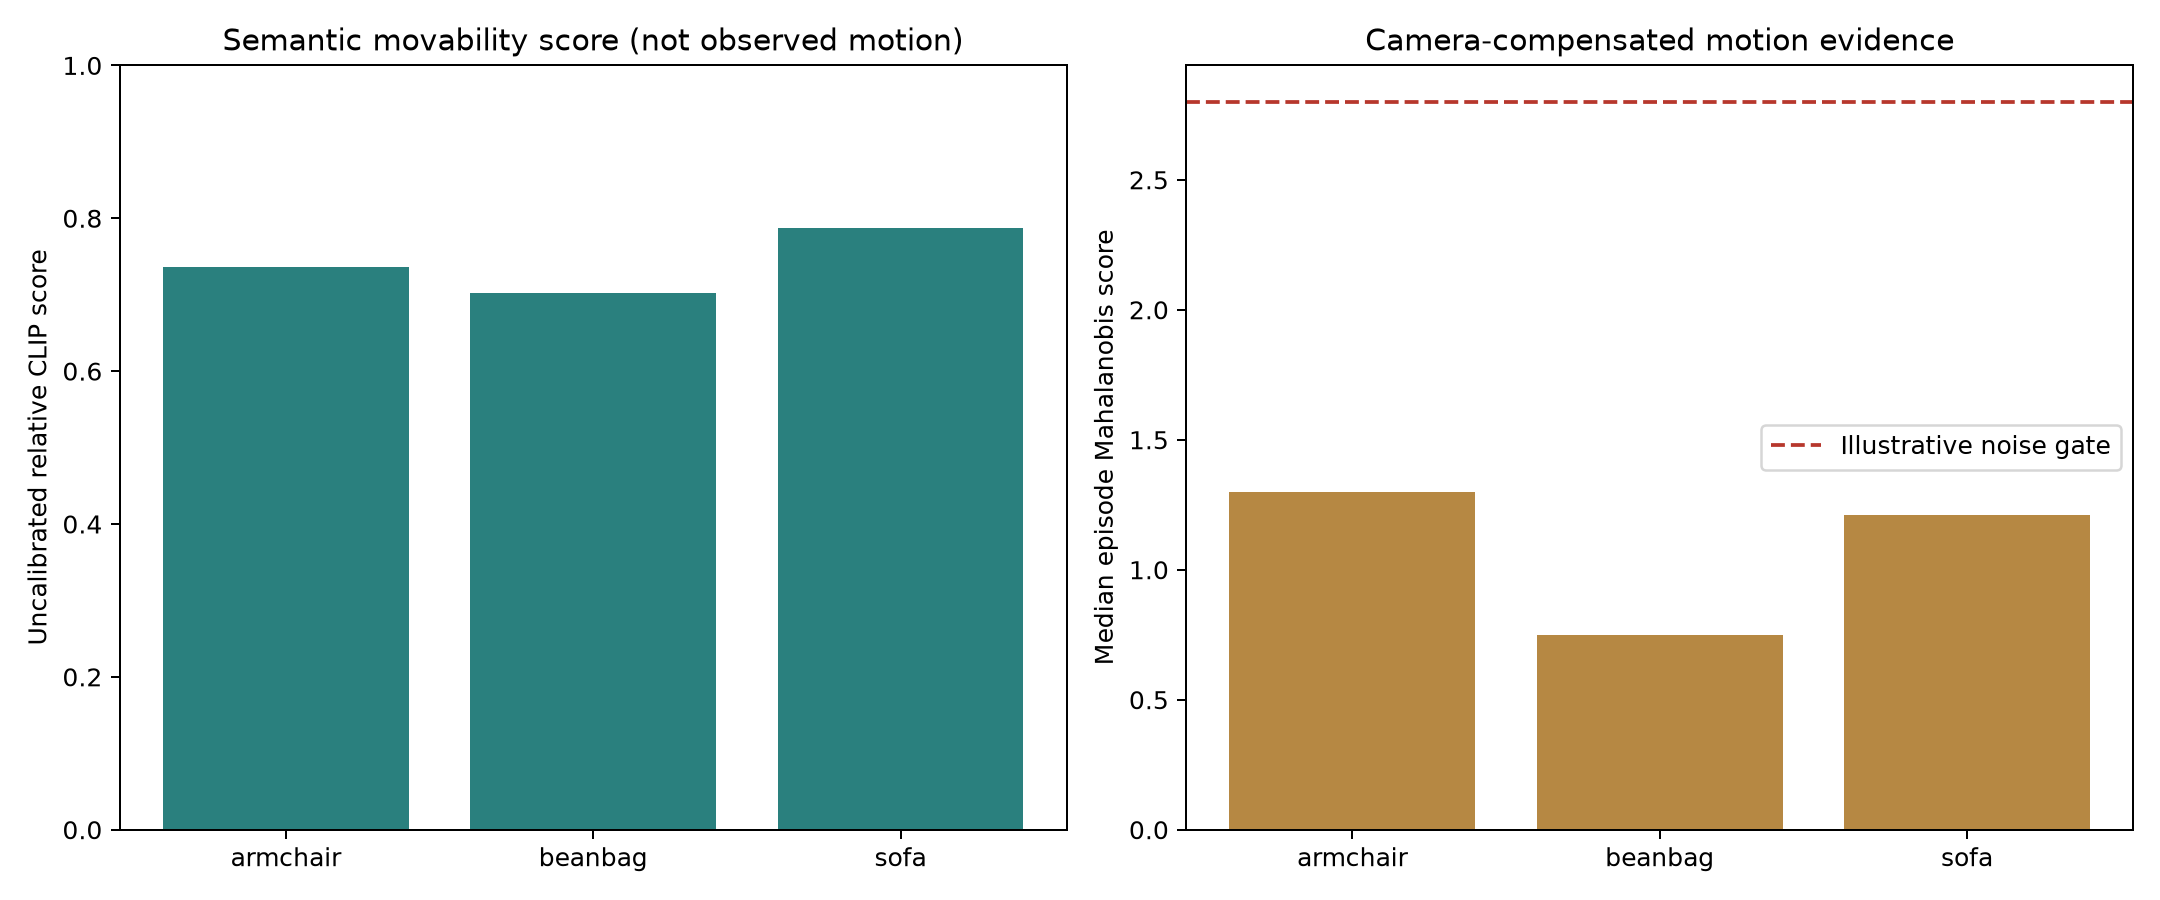

In [8]:
import motion_map
motion_map.main()
elements = json.loads((mapping.OUT / "vlmm_elements.json").read_text())
display(pd.DataFrame(elements)[["class_name", "observed_motion_score", "movability_prior_score", "motion_class", "eligible_motion_pairs"]])
print(json.dumps(json.loads((mapping.OUT / "vlmm_queries.json").read_text()), indent=2))
display(Image(filename=str(mapping.OUT / "vlmm_motion_attributes.png")))

## Replay and regression verification

This video uses the final map and replays the camera trajectory; it is not an online-building benchmark. Tests cover the geometric convention, calibration recovery, monotonicity and evidence double counting.

In [9]:
mapping.render_replay(poses)
display(Video(filename=str(mapping.OUT / "repaired_room_replay.mp4"), embed=True))
import unittest, test_mapping
suite = unittest.defaultTestLoader.loadTestsFromModule(test_mapping)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()
print("Completed: saved map, language evidence, holdout metrics, replay and passing regression tests.")

test_arkit_axes_and_triangulation (test_mapping.MappingRegressionTests.test_arkit_axes_and_triangulation) ... 

ok


test_decoder_uncertainty_suppresses_axial_noise_not_lateral_motion (test_mapping.MappingRegressionTests.test_decoder_uncertainty_suppresses_axial_noise_not_lateral_motion) ... 

ok


test_motion_noise_and_true_displacement_are_distinct (test_mapping.MappingRegressionTests.test_motion_noise_and_true_displacement_are_distinct) ... 

...

ok


test_weak_frames_cannot_reverse_depth_order (test_mapping.MappingRegressionTests.test_weak_frames_cannot_reverse_depth_order) ... 

ok


----------------------------------------------------------------------
Ran 9 tests in 5.026s

OK


Completed: saved map, language evidence, holdout metrics, replay and passing regression tests.


## Research interpretation

The strongest current result is recovering a coherent room from incorrectly interpreted exported data. Much of the gain comes from fixing axes and calibration, which is engineering, not novelty. The proposed research question is whether decoder-quality-conditioned evidence budgeting improves language localization and abstention on lossy mobile LiDAR exports across scenes. The unfiltered tail remains worse than the camera-only intermediate method; filtering trades completeness for support. Use scene-level splits and metric/semantic ground truth before publication claims.

References: [VLMaps](https://arxiv.org/abs/2210.05714), [Affine Corrections](https://arxiv.org/abs/2501.05446), [Semantic Mapping Overconfidence](https://motion.cs.illinois.edu/papers/ICRA2024_Marques_OverconfidenceSemanticMapping.pdf), [SCOUT](https://arxiv.org/abs/2606.06721).

The stronger, narrower candidate is export-calibration-aware motion grounding. It needs dynamic scenes with known ground truth; the current sequence does not establish uniqueness or motion recall.